# CRISP-DM: a capacity-limited customer retention queue

This project asks whether a telecom retention team can prioritize a review queue covering at most 30% of customers. Churn is a retrospective binary outcome. The data cannot establish whether contacting a customer prevents churn. Business figures, staffing rules, and acceptance gates are explicit educational assumptions.

The six CRISP-DM phases are developed below. Read `REPORT.md` for the full task-to-artifact mapping, source assumptions, risks, and deployment plan. All reported results are recomputed by this notebook. A local Jupyter run is supplied, while your own Colab run and manual verification remain submission tasks.

**Colab instructions:** upload this `.ipynb` to Colab, use a Python 3.11+ CPU runtime, and select Runtime → Run all. The source CSV downloads from Kaggle and is checked against the saved SHA-256. If Kaggle blocks automatic download, download the named CSV from the dataset page and upload it into `cmpe_project_runs/01_crisp_dm_telco/data/` under the current working directory (or use the exact path printed by the acquisition error). No API key is embedded. Save your executed notebook and download the resulting artifacts before ending the session.

In [1]:
import sys, subprocess, importlib.metadata as package_metadata
if sys.version_info < (3,11):raise RuntimeError("Python 3.11 or newer is required")
required={"numpy":"2.3.5","pandas":"2.2.3","scikit-learn":"1.8.0","matplotlib":"3.10.8","scipy":"1.17.0","joblib":"1.5.3"}
module_names={"numpy":"numpy","pandas":"pandas","scikit-learn":"sklearn","matplotlib":"matplotlib","scipy":"scipy","joblib":"joblib"}
mismatches=[]
for name,version in required.items():
    try:
        if package_metadata.version(name)!=version:mismatches.append(name)
    except package_metadata.PackageNotFoundError:mismatches.append(name)
already_loaded=[name for name in mismatches if module_names[name] in sys.modules]
if mismatches:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*[f"{name}=={required[name]}" for name in mismatches]])
if already_loaded:
    raise RuntimeError("Dependencies were replaced after import: "+", ".join(already_loaded)+". Restart the runtime, then Run all.")
print("Dependency setup complete. Loaded library versions are checked in the next cell.")

Dependency setup complete. Loaded library versions are checked in the next cell.


## Setup and reproducibility

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [2]:
from pathlib import Path
import json, hashlib, urllib.request, zipfile, io, sys, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix,
    precision_score, recall_score, f1_score, mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance
SEED = 42
# Notebook runs in the current working directory; scripts run beside their source.
ROOT = Path.cwd() / "cmpe_project_runs" / '01_crisp_dm_telco'
for folder in ["data", "artifacts", "figures", "deployment"]:
    (ROOT / folder).mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=["black", "0.45", "0.7"]), "font.size": 10})
def save_json(name, value):
    (ROOT / "artifacts" / name).write_text(json.dumps(value, indent=2, default=str))
def save_table(name, value):
    value.to_csv(ROOT / "artifacts" / name, index=False)
    print(name + "\n" + value.to_string(index=False))
def save_fig(name):
    plt.tight_layout()
    plt.savefig(ROOT / "figures" / name, dpi=140, bbox_inches="tight")
    plt.close()
def interval(y, pred, metric, repeats=2000, require_two_classes=False):
    rng = np.random.default_rng(SEED)
    values = []
    y, pred = np.asarray(y), np.asarray(pred)
    for _ in range(repeats):
        idx = rng.integers(0, len(y), len(y))
        if not require_two_classes or len(np.unique(y[idx])) > 1:
            values.append(metric(y[idx], pred[idx]))
    return np.quantile(values, [.025, .975]).tolist()
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib", "scipy", "joblib"]}
import scipy, sklearn
loaded_versions = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "matplotlib": matplotlib.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__}
if loaded_versions != versions:
    raise RuntimeError("Loaded modules differ from installed distributions. Restart the runtime.")
save_json("environment.json", {"python": platform.python_version(), "packages": versions,
    "loaded_module_versions": loaded_versions, "seed": SEED})
print("Environment:", versions)



Environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'scipy': '1.17.0', 'joblib': '1.5.3'}


## Acquire and verify the source data

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [3]:
SOURCE = 'blastchar/telco-customer-churn'
FILENAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
EXPECTED_SHA256 = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
data_path = ROOT / "data" / FILENAME
if not data_path.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/" + SOURCE
    try:
        with urllib.request.urlopen(url, timeout=90) as response:
            archive = response.read()
        with zipfile.ZipFile(io.BytesIO(archive)) as zipped:
            data_path.write_bytes(zipped.read(FILENAME))
    except Exception as exc:
        raise RuntimeError("Download failed. Download the CSV from https://www.kaggle.com/datasets/" + SOURCE +
                           " and place it in " + str(data_path)) from exc
actual_sha = hashlib.sha256(data_path.read_bytes()).hexdigest()
if actual_sha != EXPECTED_SHA256:
    raise ValueError("Source checksum changed. Review the dataset revision before rerunning.")
raw = pd.read_csv(data_path)
print("Verified source:", SOURCE, "shape:", raw.shape, "SHA256:", actual_sha)
save_json("source_validation.json", {"source": SOURCE, "sha256": actual_sha, "raw_shape": raw.shape})



Verified source: blastchar/telco-customer-churn shape: (7043, 21) SHA256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


## Phase 1: Business understanding and measurable objectives

The queue capacity, retrospective success criteria, and scope are declared before fitting. A deployment decision additionally needs current outcome timing and intervention evidence.

In [4]:
# A proposed retention queue, not an estimate of treatment effect.
def select_contact_queue(probability, threshold, capacity_fraction=.30):
    """Apply the frozen threshold, then cap eligible rows by risk and stable input order."""
    probability = np.asarray(probability, dtype=float)
    if not 0 <= capacity_fraction <= 1:
        raise ValueError("capacity_fraction must be within 0-1")
    eligible = np.flatnonzero(probability >= threshold)
    ranked = eligible[np.argsort(-probability[eligible], kind="stable")]
    selected = np.zeros(len(probability), dtype=bool)
    selected[ranked[:int(np.floor(capacity_fraction * len(probability)))]] = True
    return selected

BUSINESS = {"decision": "Rank a monthly review queue for retention staff",
    "capacity_fraction": .30, "minimum_recall": .50,
    "success": "Test average precision exceeds prevalence and recall >= 0.50 at a validation-frozen threshold",
    "scope": "Retrospective demonstration; no randomized retention outcomes or timestamps"}
save_json("business_objectives.json", BUSINESS)
print(BUSINESS)



{'decision': 'Rank a monthly review queue for retention staff', 'capacity_fraction': 0.3, 'minimum_recall': 0.5, 'success': 'Test average precision exceeds prevalence and recall >= 0.50 at a validation-frozen threshold', 'scope': 'Retrospective demonstration; no randomized retention outcomes or timestamps'}


## Phase 2: Data understanding and train-only exploration

Perform fixed schema checks, then reserve validation and test rows before examining associations. The contract summary uses training rows. Eleven blank TotalCharges values require numeric conversion and imputation, rather than treating blanks as a category.

In [5]:
assert raw.customerID.is_unique and set(raw.Churn.unique()) == {"Yes", "No"}
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df.TotalCharges, errors="coerce")
assert df.tenure.ge(0).all() and df.MonthlyCharges.ge(0).all()
y = df.Churn.eq("Yes").astype(int)
train_ids, rest_ids = train_test_split(df.index, test_size=.4, random_state=SEED, stratify=y)
val_ids, test_ids = train_test_split(rest_ids, test_size=.5, random_state=SEED, stratify=y.loc[rest_ids])
assert not (set(train_ids) & set(test_ids) or set(val_ids) & set(test_ids) or set(train_ids) & set(val_ids))
pd.DataFrame({"row_index":list(train_ids)+list(val_ids)+list(test_ids),
    "partition":["train"]*len(train_ids)+["validation"]*len(val_ids)+["test"]*len(test_ids)}).to_csv(ROOT/"artifacts/split_manifest.csv",index=False)
quality = {"rows":len(raw), "columns":len(raw.columns), "missing_after_numeric_conversion":df.isna().sum().to_dict(),
    "duplicate_ids":int(raw.customerID.duplicated().sum()), "exact_duplicate_rows":int(raw.duplicated().sum()),
    "train_n":len(train_ids), "validation_n":len(val_ids), "test_n":len(test_ids),
    "train_prevalence":float(y.loc[train_ids].mean()),
    "zero_tenure_with_missing_total":int(((df.tenure==0)&df.TotalCharges.isna()).sum())}
save_json("data_quality.json",quality)
print("Data quality:",json.dumps(quality))
summary = df.loc[train_ids].groupby("Contract").agg(n=("Churn","size"),churn_rate=("Churn",lambda s:s.eq("Yes").mean()))
save_table("train_contract_summary.csv",summary.reset_index())
summary.churn_rate.plot.bar(color="0.35",ylabel="Observed churn fraction",title="Training data: contract and churn")
save_fig("contract_churn.png")
df.loc[train_ids,["tenure","MonthlyCharges","TotalCharges"]].hist(color="0.4",figsize=(9,3),bins=25)
save_fig("numeric_distributions.png")



Data quality: {"rows": 7043, "columns": 21, "missing_after_numeric_conversion": {"customerID": 0, "gender": 0, "SeniorCitizen": 0, "Partner": 0, "Dependents": 0, "tenure": 0, "PhoneService": 0, "MultipleLines": 0, "InternetService": 0, "OnlineSecurity": 0, "OnlineBackup": 0, "DeviceProtection": 0, "TechSupport": 0, "StreamingTV": 0, "StreamingMovies": 0, "Contract": 0, "PaperlessBilling": 0, "PaymentMethod": 0, "MonthlyCharges": 0, "TotalCharges": 11, "Churn": 0}, "duplicate_ids": 0, "exact_duplicate_rows": 0, "train_n": 4225, "validation_n": 1409, "test_n": 1409, "train_prevalence": 0.26532544378698225, "zero_tenure_with_missing_total": 11}
train_contract_summary.csv
      Contract    n  churn_rate
Month-to-month 2304    0.430556
      One year  896    0.110491
      Two year 1025    0.029268


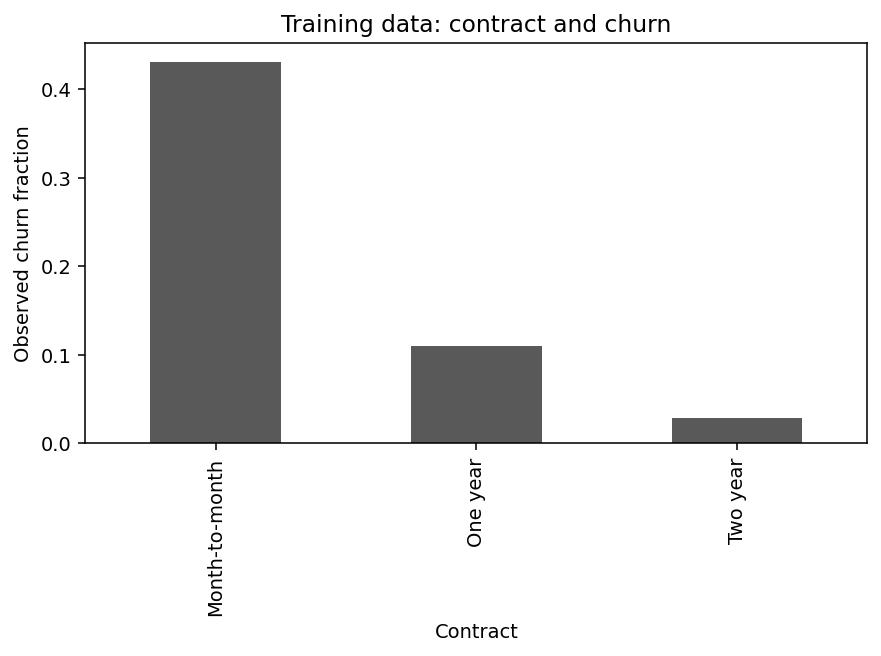

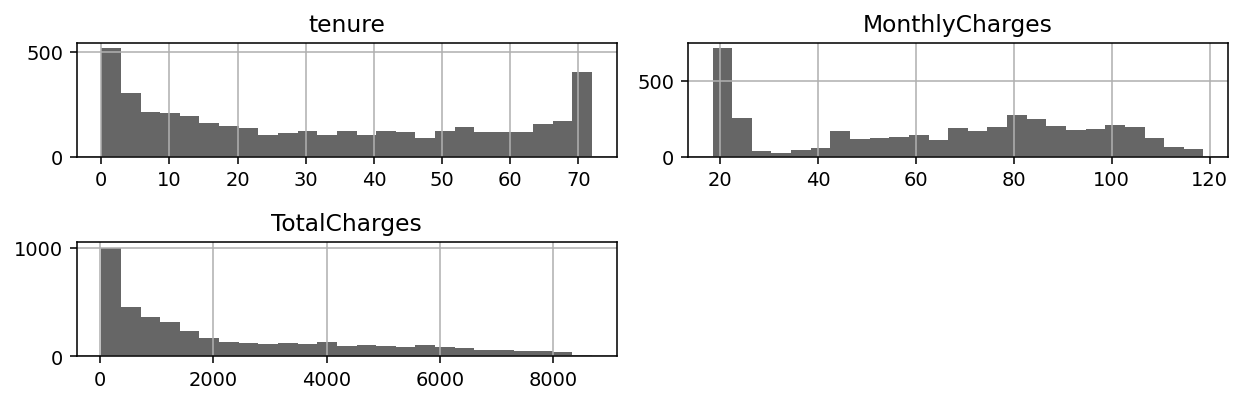

In [6]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'contract_churn.png')))
display(Image(filename=str(ROOT / "figures" / 'numeric_distributions.png')))

## Phase 3: Data preparation and leakage controls

The pipeline learns all imputation, encoding, and scaling within each training fold. Customer IDs and two demographic audit fields are excluded. Other fields can still act as proxies, so exclusion alone does not prove fairness.

In [7]:
excluded = ["customerID","Churn","gender","SeniorCitizen"]
X = df.drop(columns=excluded)
num = ["tenure","MonthlyCharges","TotalCharges"]
cat = [c for c in X if c not in num]
pre = ColumnTransformer([
    ("num",Pipeline([("impute",SimpleImputer(strategy="median",add_indicator=True)),("scale",StandardScaler())]),num),
    ("cat",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),cat)])
save_json("feature_contract.json",{"required_columns":X.columns.tolist(),"numeric":num,"categorical":cat,
    "excluded":excluded,"imputation":"Training-fold median and most frequent category","scaling":"Training-fold standardization",
    "dictionary":"DATA_DICTIONARY.md","numeric_domain":"Nonnegative charges and integer nonnegative tenure; missing numeric values imputed; blank numeric strings are missing"})
print("Predictors:", X.columns.tolist())



Predictors: ['Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


## Phase 4: Modeling with training cross-validation

Three logistic settings and two forest settings compete through three training-only folds. Average precision is the primary ranking metric. A validation-only threshold maximizes F2 among queues meeting the 30% capacity constraint. Test outcomes do not choose a model or threshold.

In [8]:
pipe = Pipeline([("prepare",pre),("model",LogisticRegression(max_iter=1500,random_state=SEED))])
grid = [{"model":[LogisticRegression(max_iter=1500,random_state=SEED)],"model__C":[.1,1,10]},
        {"model":[RandomForestClassifier(n_estimators=120,max_depth=10,n_jobs=1,random_state=SEED)],"model__min_samples_leaf":[5,15]}]
search = GridSearchCV(pipe,grid,scoring="average_precision",cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1)
search.fit(X.loc[train_ids],y.loc[train_ids])
model = search.best_estimator_
save_table("cv_results.csv",pd.DataFrame(search.cv_results_)[["params","mean_test_score","std_test_score","rank_test_score"]])
baseline = DummyClassifier(strategy="prior").fit(X.loc[train_ids],y.loc[train_ids])
vp = model.predict_proba(X.loc[val_ids])[:,1]
# Pick the highest validation F2 among queues that stay within the 30% capacity.
rows=[]
for threshold in np.unique(np.r_[vp,1.000001]):
    pred = vp >= threshold
    if pred.mean() <= BUSINESS["capacity_fraction"]:
        precision=precision_score(y.loc[val_ids],pred,zero_division=0)
        recall=recall_score(y.loc[val_ids],pred,zero_division=0)
        f2=5*precision*recall/(4*precision+recall) if precision+recall else 0
        rows.append({"threshold":threshold,"contact_fraction":pred.mean(),"precision":precision,"recall":recall,"F2":f2})
thresholds=pd.DataFrame(rows).sort_values(["F2","threshold"],ascending=[False,False])
thresholds.to_csv(ROOT/"artifacts/threshold_search.csv",index=False)
threshold=float(thresholds.iloc[0].threshold)
print("Selected:",search.best_params_,"Frozen validation threshold:",threshold)



cv_results.csv
                                                                                                                                            params  mean_test_score  std_test_score  rank_test_score
                                                                    {'model': LogisticRegression(max_iter=1500, random_state=42), 'model__C': 0.1}         0.661688        0.037122                5
                                                                      {'model': LogisticRegression(max_iter=1500, random_state=42), 'model__C': 1}         0.663837        0.036881                3
                                                                     {'model': LogisticRegression(max_iter=1500, random_state=42), 'model__C': 10}         0.663072        0.035699                4
 {'model': RandomForestClassifier(max_depth=10, n_estimators=120, n_jobs=1,
                       random_state=42), 'model__min_samples_leaf': 5}         0.664467        0.027285                2


## Phase 5: Evaluation against the original objectives

Use the frozen pipeline and threshold once on held-out rows. Report confusion counts, precision, recall, average precision, ROC AUC, Brier loss, and bootstrap uncertainty. Group comparisons are descriptive, with denominators included. Feature importance is evaluated on validation data.

In [9]:
truth=y.loc[test_ids].to_numpy()
prob=model.predict_proba(X.loc[test_ids])[:,1]
threshold_pred=prob>=threshold
pred=select_contact_queue(prob,threshold,BUSINESS["capacity_fraction"])
baseprob=baseline.predict_proba(X.loc[test_ids])[:,1]
tn,fp,fn,tp=confusion_matrix(truth,pred).ravel()
order=np.argsort(-prob,kind="stable"); n_top=int(np.floor(len(prob)*.30))
metrics={"selected_model":str(search.best_params_),"threshold":threshold,"test_n":len(truth),
    "average_precision":average_precision_score(truth,prob),"baseline_AP":average_precision_score(truth,baseprob),
    "test_prevalence":truth.mean(),"ROC_AUC":roc_auc_score(truth,prob),"Brier":brier_score_loss(truth,prob),
    "precision":precision_score(truth,pred,zero_division=0),"recall":recall_score(truth,pred),"F1":f1_score(truth,pred),
    "contact_fraction":pred.mean(),"TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp),
    "top30_recall":float(truth[order[:n_top]].sum()/truth.sum()),
    "top30_lift":float(truth[order[:n_top]].mean()/truth.mean()),
    "AP_bootstrap_95pct":interval(truth,prob,average_precision_score,require_two_classes=True),
    "retrospective_gate_passed":bool(average_precision_score(truth,prob)>truth.mean() and recall_score(truth,pred)>=.5 and pred.sum()<=int(np.floor(.30*len(pred)))),
    "bootstrap_repeats":2000,"bootstrap_seed":SEED,
    "policy":"Frozen threshold followed by floor(0.30*n) cap with stable risk ranking",
    "threshold_only_contact_fraction":float(threshold_pred.mean()),
    "threshold_only_recall":recall_score(truth,threshold_pred),
    "threshold_only_precision":precision_score(truth,threshold_pred,zero_division=0),
    "policy_equals_threshold_on_test":bool(np.array_equal(pred,threshold_pred)),
    "production_approved":False}
save_json("metrics.json",metrics);print(json.dumps(metrics,indent=2))
groups=[]
for field in ["gender","SeniorCitizen"]:
    for value in df.loc[test_ids,field].unique():
        idx=df.loc[test_ids,field].eq(value).to_numpy()
        groups.append({"field":field,"group":str(value),"n":int(idx.sum()),"positives":int(truth[idx].sum()),
            "recall":recall_score(truth[idx],pred[idx],zero_division=0),"selection_rate":pred[idx].mean()})
save_table("group_audit.csv",pd.DataFrame(groups))
importance=permutation_importance(model,X.loc[val_ids],y.loc[val_ids],scoring="average_precision",n_repeats=4,random_state=SEED)
save_table("validation_importance.csv",pd.DataFrame({"feature":X.columns,"AP_decrease":importance.importances_mean}).sort_values("AP_decrease",ascending=False))
plt.hist(prob[truth==0],bins=20,alpha=.6,color="0.7",label="Stayed")
plt.hist(prob[truth==1],bins=20,alpha=.6,color="0.2",label="Churned")
plt.axvline(threshold,color="black",linestyle="--",label="Frozen threshold");plt.legend();plt.xlabel("Estimated churn probability")
save_fig("test_probabilities.png")


{
  "selected_model": "{'model': RandomForestClassifier(max_depth=10, n_estimators=120, n_jobs=1,\n                       random_state=42), 'model__min_samples_leaf': 15}",
  "threshold": 0.3823721103201337,
  "test_n": 1409,
  "average_precision": 0.6296712898679541,
  "baseline_AP": 0.2654364797728886,
  "test_prevalence": 0.2654364797728886,
  "ROC_AUC": 0.8323206489446898,
  "Brier": 0.14055710330415724,
  "precision": 0.5819477434679335,
  "recall": 0.6550802139037433,
  "F1": 0.6163522012578616,
  "contact_fraction": 0.29879347054648686,
  "TN": 859,
  "FP": 176,
  "FN": 129,
  "TP": 245,
  "top30_recall": 0.6550802139037433,
  "top30_lift": 2.1872227995032567,
  "AP_bootstrap_95pct": [
    0.5781768312756883,
    0.6826855442510635
  ],
  "retrospective_gate_passed": true,
  "bootstrap_repeats": 2000,
  "bootstrap_seed": 42,
  "policy": "Frozen threshold followed by floor(0.30*n) cap with stable risk ranking",
  "threshold_only_contact_fraction": 0.29879347054648686,
  "threshol

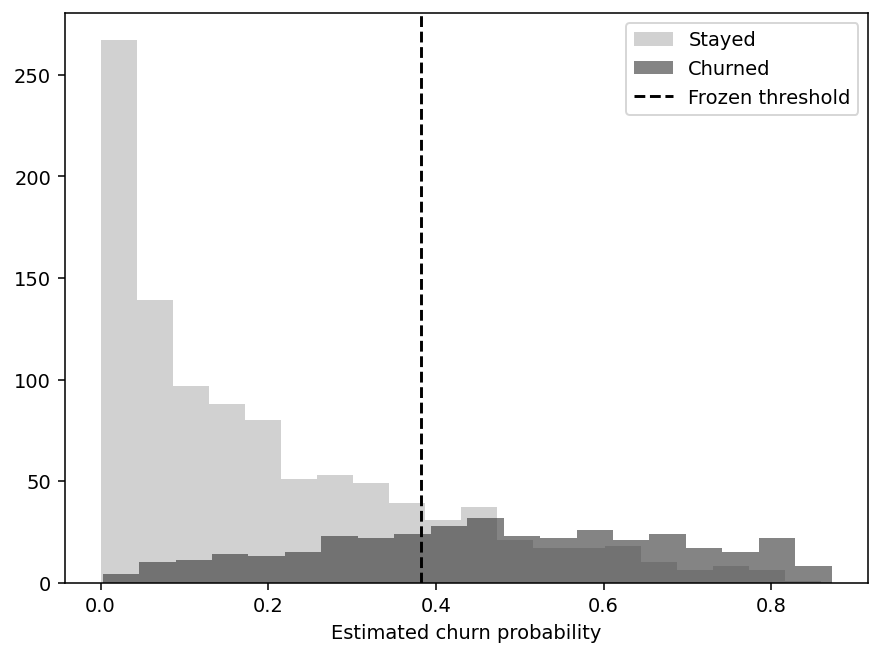

In [10]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'test_probabilities.png')))

## Phase 6: Deployment demonstration, serialization, and smoke check

Serialize the complete fitted pipeline and check prediction equality after loading it. The batch scorer adds a hard 30% contact cap. Production operation needs a governed pilot, monitored data, and an outcome definition verified at scoring time.

In [11]:
bundle={"model":model,"threshold":threshold,"features":X.columns.tolist(),"task":"classification"}
joblib.dump(bundle,ROOT/"artifacts/model.joblib")
X.loc[test_ids].head(5).to_csv(ROOT/"deployment/example_input.csv",index=False)
loaded=joblib.load(ROOT/"artifacts/model.joblib")
np.testing.assert_allclose(loaded["model"].predict_proba(X.loc[test_ids].head(5))[:,1],prob[:5])
save_json("analysis_verification.json",{"disjoint_splits":True,"unique_customer_ids":True,
    "serialized_predictions_match":True,"all_probabilities_valid":bool(((prob>=0)&(prob<=1)).all()),
    "student_manual_review":"PENDING","colab_runtime_execution":"PENDING; analysis execution does not establish Colab execution"})
print("Model saved and reloaded successfully. Production deployment remains a proposed supervised pilot.")


Model saved and reloaded successfully. Production deployment remains a proposed supervised pilot.


## Batch scoring smoke demonstration

The following cell includes the complete scorer, so the notebook works without a repository checkout. It loads the saved pipeline, checks required columns, and scores the example rows. Replace the example CSV with a fresh input after checking the feature contract.

In [12]:
"""Run from any directory: python score.py INPUT.csv OUTPUT.csv."""
from pathlib import Path
import argparse
import csv
import json
import numpy as np
import pandas as pd
import joblib


def select_contact_queue(probability, threshold, capacity_fraction=.30):
    """Apply the frozen threshold, then cap eligible rows by risk and stable input order."""
    probability = np.asarray(probability, dtype=float)
    if not 0 <= capacity_fraction <= 1:
        raise ValueError("capacity_fraction must be within 0-1")
    eligible = np.flatnonzero(probability >= threshold)
    ranked = eligible[np.argsort(-probability[eligible], kind="stable")]
    selected = np.zeros(len(probability), dtype=bool)
    selected[ranked[:int(np.floor(capacity_fraction * len(probability)))]] = True
    return selected


def read_scoring_csv(input_csv):
    """Reject ambiguous headers and ragged records before pandas can infer an index."""
    with open(input_csv, newline="", encoding="utf-8-sig") as handle:
        reader = csv.reader(handle, strict=True)
        try:
            header = next((row for row in reader if row and not (len(row)==1 and not row[0].strip())), None)
            if header is None:
                raise ValueError("CSV has no header")
            if any(not name.strip() for name in header):
                raise ValueError("CSV header names must be nonempty")
            if len(set(header)) != len(header):
                raise ValueError("CSV contains duplicate header names")
            for row in reader:
                if not row or (len(row)==1 and not row[0].strip()):
                    continue
                if len(row) != len(header):
                    raise ValueError(f"CSV record ending at line {reader.line_num} has {len(row)} fields; expected {len(header)}")
        except csv.Error as exc:
            raise ValueError("Malformed CSV structure: " + str(exc)) from exc
    return pd.read_csv(input_csv)


def score(input_csv, output_csv, model_path=None):
    root=ROOT
    bundle=joblib.load(model_path or root/'artifacts/model.joblib')
    data=read_scoring_csv(input_csv)
    missing=set(bundle['features'])-set(data.columns)
    if missing:raise ValueError('Required columns missing: '+', '.join(sorted(missing)))
    data=data[bundle['features']].copy()
    task=bundle['task']
    if task=='classification':
        numeric=['tenure','MonthlyCharges','TotalCharges']
    else:
        numeric=bundle['features']
    for col in numeric:
        normalized=data[col].replace(r'^\s*$',np.nan,regex=True)
        converted=pd.to_numeric(normalized,errors='coerce')
        invalid=normalized.notna() & converted.isna()
        if invalid.any():raise ValueError('Non-numeric values in '+col)
        if np.isinf(converted.dropna()).any():raise ValueError('Infinite values in '+col)
        data[col]=converted
    if len(data)==0:raise ValueError('The input has no rows')
    if task=='classification':
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['tenure'].dropna().mod(1).ne(0).any():raise ValueError('tenure must contain integer months')
    if task=='regression':
        if data[numeric].isna().all(axis=1).any():raise ValueError('At least one assay is required in every row')
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['density'].dropna().le(0).any():raise ValueError('density must be positive')
        if not data['pH'].dropna().between(0,14).all():raise ValueError('pH must be within 0-14 for this demo')
        if not data['alcohol'].dropna().between(0,100).all():raise ValueError('alcohol must be within 0-100 percent')
    numeric_missing_count=data[numeric].isna().sum(axis=1).to_numpy()
    model=bundle['model']
    if task=='classification':
        probability=model.predict_proba(data)[:,1]
        threshold=bundle['threshold']
        contact=select_contact_queue(probability,threshold,.30)
        output=pd.DataFrame({'input_row':np.arange(len(data)),'churn_probability':probability,
                             'above_frozen_threshold':probability>=threshold,'contact_queue':contact})
    elif task=='regression':
        output=pd.DataFrame({'input_row':np.arange(len(data)),
                             'predicted_quality':np.clip(model.predict(data),*bundle['clip'])})
    else:
        if data.isna().any().any():raise ValueError('Clustering input requires complete numeric fields')
        if (data['Annual Income (k$)']<=0).any() or not data['Spending Score (1-100)'].between(1,100).all():
            raise ValueError('Income must be positive and spending score must be within 1-100')
        output=pd.DataFrame({'input_row':np.arange(len(data)),'cluster':model.predict(data)})
    output['numeric_missing_count']=numeric_missing_count
    output.to_csv(output_csv,index=False)
    print(output.to_string(index=False))
    return output



score(ROOT / "deployment/example_input.csv", ROOT / "deployment/example_output.csv")


 input_row  churn_probability  above_frozen_threshold  contact_queue  numeric_missing_count
         0           0.112385                   False          False                      0
         1           0.214780                   False          False                      0
         2           0.205408                   False          False                      0
         3           0.536669                    True           True                      0
         4           0.060321                   False          False                      0


## Review and submission evidence

Two internal self-review passes are documented in `reviews/INTERNAL_REVISIONS.md`. They are not Claude/GPT-5 critiques. Use `reviews/EXTERNAL_CRITIC_PROMPTS.md` to obtain two genuine external rounds for **each section**, save their responses, implement the corrections, and rerun. Complete `MANUAL_VERIFICATION.md` yourself. This notebook has not been run inside Google Colab or SAS by the assistant. Article and video files are drafts for you to publish and record.

## Export generated artifacts

Each project uses its own working directory. This ZIP includes generated tables, models, figures and scoring outputs; the full reports and source references remain in the assignment package. In Colab the ZIP is downloaded automatically.

In [13]:
import zipfile
export_path=ROOT.parent/(ROOT.name+"_generated_artifacts.zip")
with zipfile.ZipFile(export_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for folder in ["artifacts","figures","deployment"]:
        for item in sorted((ROOT/folder).rglob("*")):
            if item.is_file():archive.write(item,item.relative_to(ROOT))
print("Generated artifact ZIP:",export_path)
try:
    from google.colab import files as colab_files
except ImportError:
    print("Outside Colab: copy the ZIP from the path above.")
else:
    colab_files.download(str(export_path))

Generated artifact ZIP: /workspace/scratch/2f6200312d13/review_work/executions/01_crisp_dm_telco/cmpe_project_runs/01_crisp_dm_telco_generated_artifacts.zip
Outside Colab: copy the ZIP from the path above.
